In [1]:
from datasets import load_dataset
import pandas as pd

## Small Dataset

In [2]:
gpt_pred = load_dataset("Eathus/github-issues-vul-detection-gpt-few-results-final-best2", split="test")
gpt_pred_df = gpt_pred.to_pandas()
gpt_pred_df = gpt_pred_df[~gpt_pred_df.duplicated(subset="issue_github_id", keep=False)]

In [3]:
y_test = gpt_pred_df['label'].values
y_pred = gpt_pred_df["gpt_is_relevant"].values

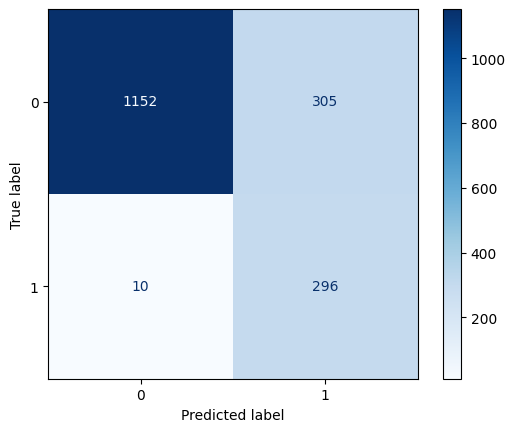

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap='Blues')

plt.savefig("tmp/confusion_matrix_small.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

In [5]:
from sklearn.metrics import accuracy_score, classification_report

y_test = gpt_pred_df.label.values
y_pred = gpt_pred_df.gpt_is_relevant

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy}")
print("Classification Report:")
print(report)

Accuracy: 0.8213272830402722
Classification Report:
              precision    recall  f1-score   support

       False       0.99      0.79      0.88      1457
        True       0.49      0.97      0.65       306

    accuracy                           0.82      1763
   macro avg       0.74      0.88      0.77      1763
weighted avg       0.90      0.82      0.84      1763



## Large Dataset

In [6]:
# Load both splits
ds = load_dataset(
    "Eathus/github-issues-vul-max-detection-gpt-few-results-final3",
    split=["train", "test"]
)

# ds is now a list: [train_dataset, test_dataset]
train_ds, test_ds = ds

# Convert each to DataFrame
train_df = train_ds.to_pandas()
test_df = test_ds.to_pandas()

# Drop duplicates if needed (like you did for test)
train_df = train_df[~train_df.duplicated(subset="issue_github_id", keep=False)]
test_df = test_df[~test_df.duplicated(subset="issue_github_id", keep=False)]

# Combine both DataFrames
gpt_pred_large_df = pd.concat([train_df, test_df], ignore_index=True)

In [7]:
y_test = gpt_pred_large_df['label'].values
y_pred = gpt_pred_large_df["gpt_is_relevant"].values

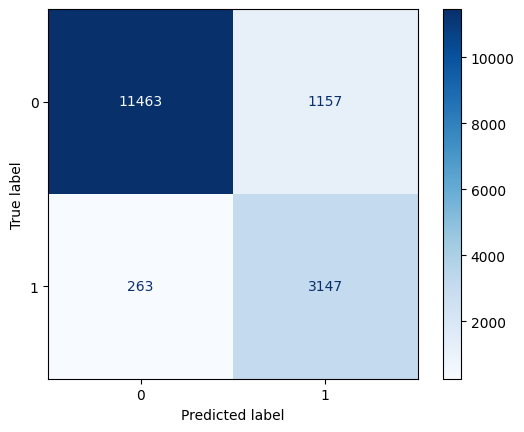

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm)
disp.plot(cmap='Blues')

plt.savefig("tmp/confusion_matrix_large.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

In [9]:
from sklearn.metrics import accuracy_score, classification_report

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy}")
print("Classification Report:")
print(report)

Accuracy: 0.9114160948222083
Classification Report:
              precision    recall  f1-score   support

       False       0.98      0.91      0.94     12620
        True       0.73      0.92      0.82      3410

    accuracy                           0.91     16030
   macro avg       0.85      0.92      0.88     16030
weighted avg       0.93      0.91      0.91     16030



In [13]:
gpt_pred_large_df.columns


Index(['cve_id', 'cve_published', 'cve_descriptions', 'cve_metrics',
       'cve_references', 'cve_configurations', 'cve_primary_cwe', 'cve_tags',
       'issue_owner_repo', 'issue_body', 'issue_title', 'issue_comments_url',
       'issue_comments_count', 'issue_created_at', 'issue_updated_at',
       'issue_html_url', 'issue_github_id', 'issue_number', 'label',
       'issue_msg', 'issue_msg_n_tokens', 'issue_embedding',
       '__index_level_0__', 'gpt_description', 'gpt_vulnerability',
       'gpt_confidence', 'gpt_is_relevant'],
      dtype='object')